# Lab 5: Clustering Techniques Using DBSCAN and Hierarchical Clustering

**Name:** Rahul Solanki
**Course:** MSCS-634-B01: Advanced Big Data and Data Mining
**Professor:** Satish Penmatsa
**Date:** November 22, 2026

## Step 1: Data Preparation and Exploration

The Wine dataset ships with scikit-learn: 178 wines from three cultivars, each described by 13 chemical measurements.
The clustering algorithms only see the 13 features. The cultivar labels are kept aside and used only to score the
clusters (homogeneity, completeness, and the Adjusted Rand Index).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.cluster.hierarchy import linkage, dendrogram, set_link_color_palette
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score, adjusted_rand_score

%config InlineBackend.figure_format = "retina"
pd.set_option("display.width", 200)

wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
class_names = [str(c) for c in wine.target_names]
df = wine.frame
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target          

In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


In [4]:
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:", dict(zip(class_names, y.value_counts().sort_index().tolist())))

Missing values: 0
Class counts: {'class_0': 59, 'class_1': 71, 'class_2': 48}


**What the exploration shows:** 178 rows, 13 numeric features plus the target, no missing values, and three classes of
59, 71 and 48 wines. The features are on very different scales (proline ranges from 278 to 1,680, hue from 0.48 to 1.71),
and both algorithms here measure Euclidean distance, so without scaling proline alone would decide the clusters.

In [5]:
# z-score standardization: every feature gets mean 0 and standard deviation 1
Z = StandardScaler().fit_transform(X)
print("Standardized shape:", Z.shape)
pd.DataFrame({"mean": Z.mean(axis=0), "std": Z.std(axis=0)}, index=X.columns).round(3).T

Standardized shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [6]:
# Shared helpers: chart style, a 2-D view for plotting, and one scoring function for every clustering result
BLUE, ORANGE, AQUA, VIOLET, MAGENTA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e87ba4", "#eda100"
COLORS = [BLUE, ORANGE, AQUA, VIOLET, MAGENTA, YELLOW]
MARKERS = ["o", "s", "^", "D", "v", "P"]          # shape repeats the cluster identity, so color is never alone
GRAY, INK, MUTED = "#8a8985", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRAY,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10})

# The clustering itself always uses all 13 standardized features; PCA is only used to draw them in 2-D
pca = PCA(n_components=2).fit(Z)
P = pca.transform(Z)
print(f"PC1 + PC2 explain {pca.explained_variance_ratio_.sum():.1%} of the variance")

def score(labels):
    """Metrics for one clustering. Noise (label -1) is left out of the silhouette, because noise is not a cluster;
    homogeneity and completeness treat noise as one extra group, which is scikit-learn's convention."""
    labels = np.asarray(labels)
    core = labels != -1
    n_clusters = len(set(labels[core]))
    sil = silhouette_score(Z[core], labels[core]) if n_clusters >= 2 else np.nan
    return {"clusters": n_clusters, "noise %": 100 * (~core).mean(), "silhouette": sil,
            "homogeneity": homogeneity_score(y, labels), "completeness": completeness_score(y, labels),
            "ARI": adjusted_rand_score(y, labels)}

def order_by_pc1(labels):
    """Renumber clusters from left to right along PC1, so colors follow position and are comparable across plots."""
    labels = np.asarray(labels)
    ids = [c for c in np.unique(labels) if c != -1]
    order = sorted(ids, key=lambda c: P[labels == c, 0].mean())
    mapping = {old: new for new, old in enumerate(order)}
    return np.array([mapping.get(l, -1) for l in labels])

def scatter(ax, labels, title, subtitle=""):
    labels = order_by_pc1(labels)
    noise = labels == -1
    if noise.any():
        ax.scatter(P[noise, 0], P[noise, 1], s=30, marker="x", c=GRAY, linewidths=1.2, zorder=2, label="noise")
    for c in range(labels.max() + 1):
        pts = P[labels == c]
        ax.scatter(pts[:, 0], pts[:, 1], s=32, c=COLORS[c % 6], marker=MARKERS[c % 6], edgecolors="white",
                   linewidths=0.6, zorder=3, label=f"cluster {c + 1}")
    subtitle = subtitle.strip()
    n_lines = subtitle.count("\n") + 1 if subtitle else 0
    ax.set_title(title, pad=6 + 14 * n_lines)       # leave room for the subtitle lines under the title
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, color=MUTED, fontsize=9, va="bottom")
    ax.set_xlabel("PC1")
    ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.13))

PC1 + PC2 explain 55.4% of the variance


## Step 2: Hierarchical Clustering

Agglomerative clustering starts with every wine as its own cluster and repeatedly merges the two closest clusters.
**Ward linkage** (scikit-learn's default) merges the pair that increases the within-cluster variance the least.

In [7]:
# Test different numbers of clusters with Ward linkage
agg_rows, agg_labels = [], {}
for n in range(2, 7):
    labels = AgglomerativeClustering(n_clusters=n, linkage="ward").fit_predict(Z)
    agg_labels[n] = labels
    agg_rows.append({"n_clusters": n, "sizes": sorted(np.bincount(labels).tolist(), reverse=True), **score(labels)})
agg_table = pd.DataFrame(agg_rows).set_index("n_clusters").drop(columns=["clusters", "noise %"])
agg_table.round(3)

,sizes,silhouette,homogeneity,completeness,ARI
n_clusters,,,,,
2,"[122, 56]",0.267,0.444,0.774,0.439
3,"[64, 58, 56]",0.277,0.790,0.783,0.790
4,"[64, 56, 30, 28]",0.226,0.790,0.649,0.657
5,"[64, 36, 30, 28, 20]",0.187,0.811,0.576,0.583
6,"[58, 36, 30, 28, 20, 6]",0.180,0.835,0.553,0.576


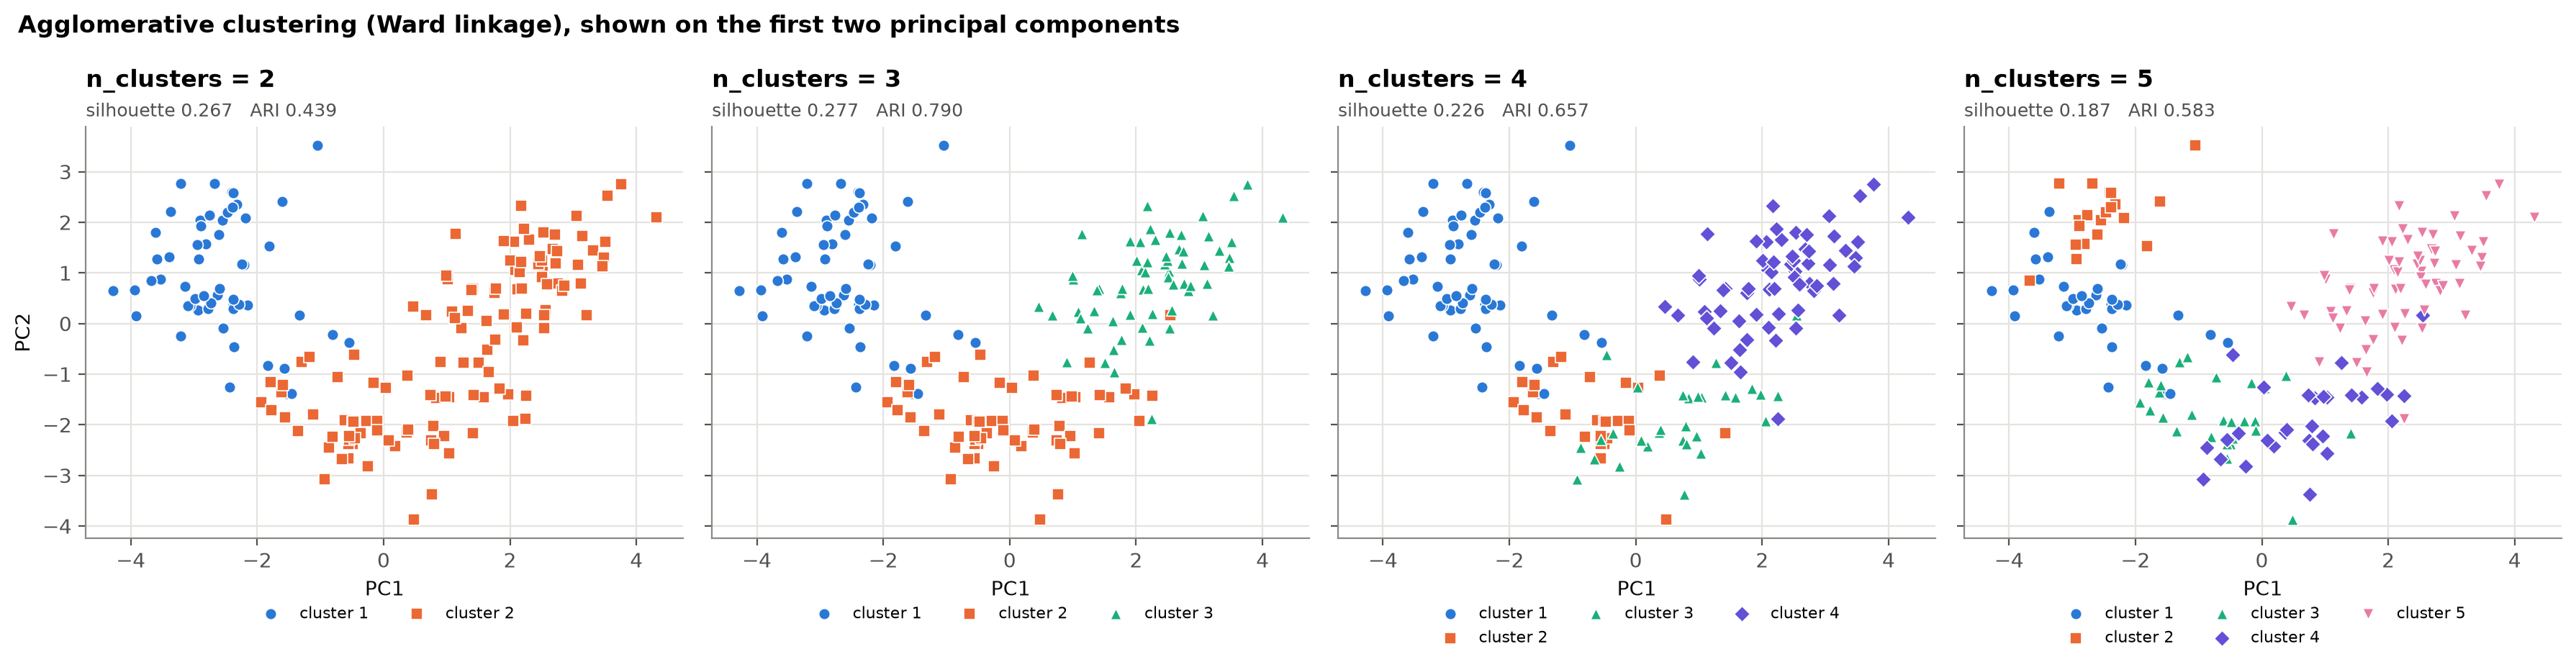

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8), sharex=True, sharey=True)
for ax, n in zip(axes, [2, 3, 4, 5]):
    r = agg_table.loc[n]
    scatter(ax, agg_labels[n], f"n_clusters = {n}", f"silhouette {r['silhouette']:.3f}   ARI {r['ARI']:.3f}")
axes[0].set_ylabel("PC2")
fig.suptitle("Agglomerative clustering (Ward linkage), shown on the first two principal components",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**n_clusters = 3 is the best choice.** It has the highest silhouette (0.277) and the best balance of homogeneity (0.790)
and completeness (0.783). With 2 clusters, two cultivars are forced together, so completeness stays high (0.774) but
homogeneity falls to 0.444. With 4 to 6 clusters, real groups are split: homogeneity creeps up (to 0.835), but
completeness drops (to 0.553) because each cultivar is spread over several clusters, and the silhouette falls to 0.180.

In [9]:
# Does the linkage method matter? Same n_clusters = 3, four linkages
link_rows = []
for method in ["ward", "complete", "average", "single"]:
    labels = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(Z)
    link_rows.append({"linkage": method, "sizes": sorted(np.bincount(labels).tolist(), reverse=True), **score(labels)})
pd.DataFrame(link_rows).set_index("linkage").drop(columns=["clusters", "noise %"]).round(3)

,sizes,silhouette,homogeneity,completeness,ARI
linkage,,,,,
ward,"[64, 58, 56]",0.277,0.790,0.783,0.790
complete,"[69, 58, 51]",0.204,0.616,0.613,0.577
average,"[174, 3, 1]",0.158,0.010,0.093,-0.005
single,"[174, 3, 1]",0.183,0.019,0.175,-0.007


The linkage matters a lot. **Ward** gives three balanced clusters. **Complete** linkage (distance between the farthest
members) is weaker (ARI 0.577). **Average** and **single** linkage fail: one cluster swallows 174 wines and the other
two hold 1 and 3 outlying wines. Single linkage merges through chains of close neighbors, and the Wine classes touch,
so everything chains together.

Heights of the last six merges: [11.38 11.72 12.23 12.57 27.65 35.4 ]


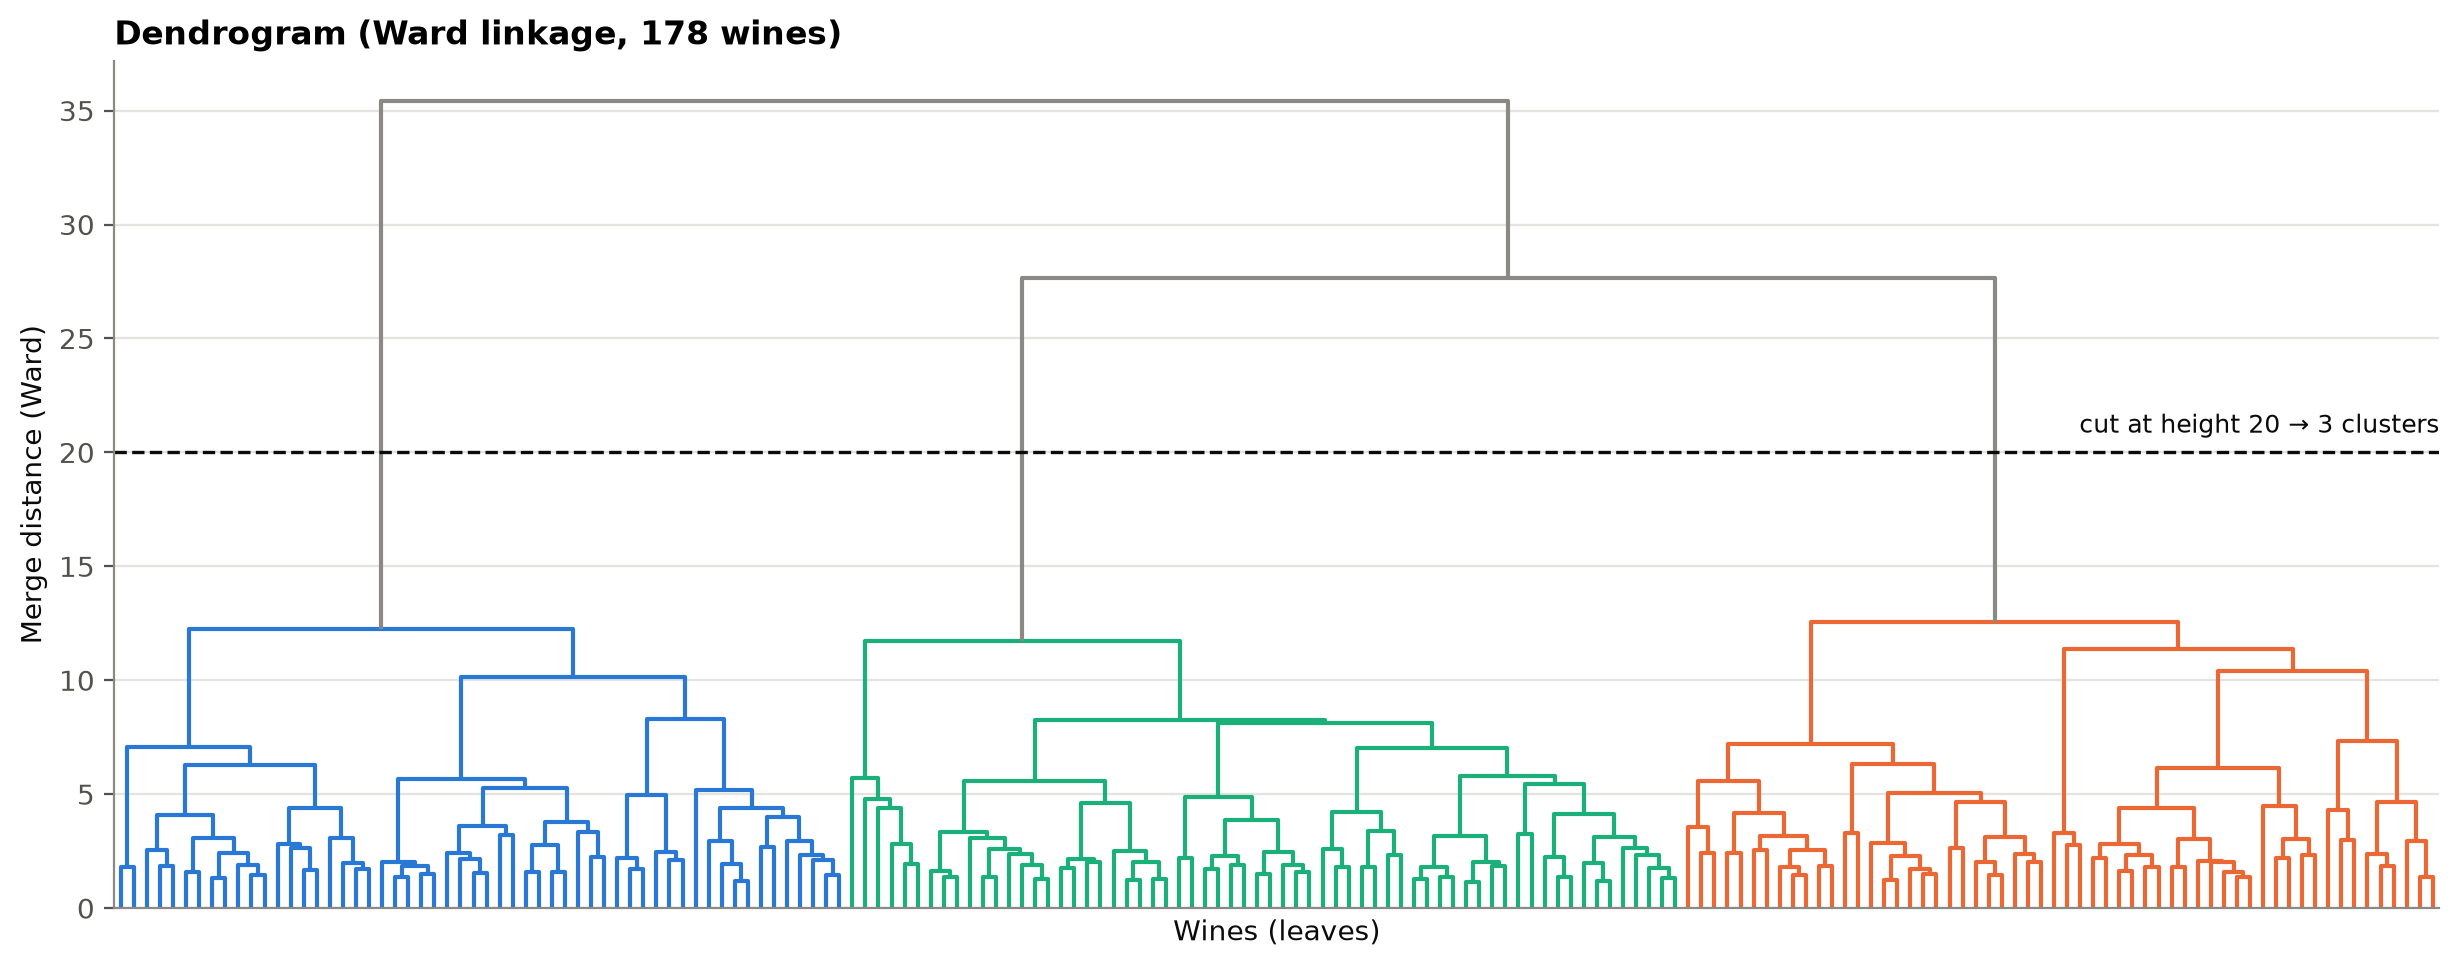

In [10]:
# Dendrogram of the Ward hierarchy (scipy's Ward on the same data gives the same 3-cluster split as scikit-learn)
L = linkage(Z, method="ward")
print("Heights of the last six merges:", L[-6:, 2].round(2))
cut = 20                                            # any height between 12.57 and 27.65 gives 3 clusters

# Color each branch like the matching cluster in the n_clusters = 3 scatter plot
first = dendrogram(L, color_threshold=cut, no_plot=True)
ward3 = order_by_pc1(agg_labels[3])
branch_colors = []
for col in dict.fromkeys(first["leaves_color_list"]):          # branches from left to right
    leaves = [leaf for leaf, c in zip(first["leaves"], first["leaves_color_list"]) if c == col]
    branch_colors.append(COLORS[np.bincount(ward3[leaves]).argmax()])
set_link_color_palette(branch_colors)
fig, ax = plt.subplots(figsize=(15, 5.5))
dendrogram(L, ax=ax, color_threshold=cut, above_threshold_color=GRAY, no_labels=True)
ax.axhline(cut, color=INK, ls="--", lw=1.2)
ax.text(ax.get_xlim()[1], cut + 0.6, f"cut at height {cut} → 3 clusters", ha="right", va="bottom", color=INK, fontsize=9)
ax.set_title("Dendrogram (Ward linkage, 178 wines)")
ax.set_ylabel("Merge distance (Ward)")
ax.set_xlabel("Wines (leaves)")
ax.grid(axis="x", visible=False)
plt.show()
set_link_color_palette(None)

**Reading the dendrogram:** each leaf at the bottom is a wine; the height of a join is how far apart the two merged
groups were. The last two merges happen at heights 27.65 and 35.40, while every earlier merge is at 12.57 or below.
That large gap means the data split naturally into **3 groups**: any horizontal cut between 12.57 and 27.65 crosses
exactly three branches. Below the cut, the many short joins show each group is made of many similar wines.
The branch colors match the n_clusters = 3 scatter plot above. The orange (mostly class_1) and aqua (mostly class_0)
groups join first, at 27.65; the blue group (mostly class_2) joins only at the very top. That closeness between
class_0 and class_1 matters again in Step 3.

In [11]:
# How the 3 Ward clusters line up with the real cultivars
pd.crosstab(y.map(dict(enumerate(class_names))), order_by_pc1(agg_labels[3]) + 1,
            rownames=["true class"], colnames=["Ward cluster"])

Ward cluster,1,2,3
true class,,,
class_0,0,0,59
class_1,8,58,5
class_2,48,0,0


## Step 3: DBSCAN Clustering

DBSCAN grows clusters from dense regions. A wine is a **core point** if at least `min_samples` wines (itself included)
lie within distance `eps`. Clusters are core points connected through each other plus their neighbors, and wines in no
dense region are labeled **noise** (-1). DBSCAN does not need the number of clusters, but it does need `eps`.

10th-neighbor distance percentiles (10, 50, 75, 90, 95): [2.11 2.56 2.89 3.55 3.89]


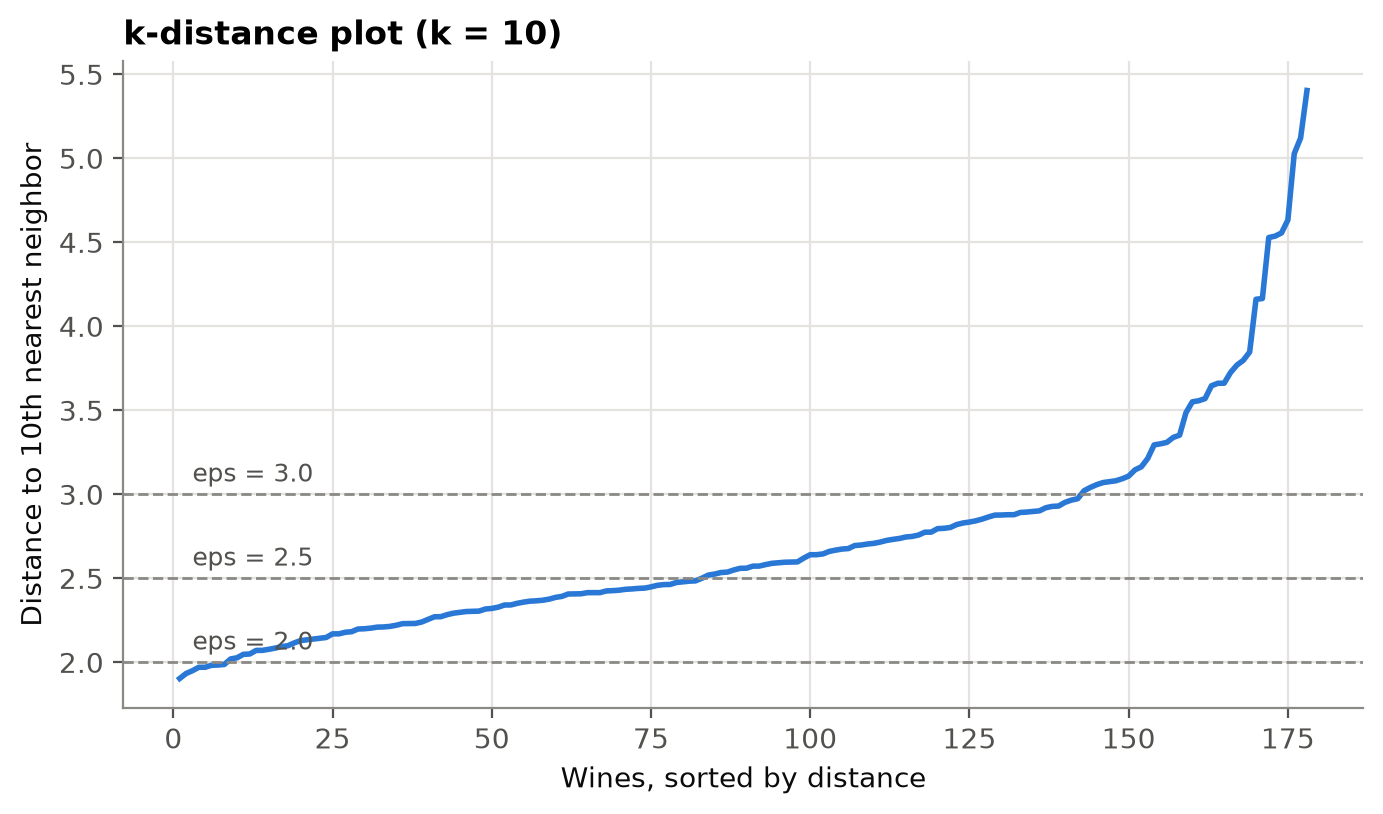

In [12]:
# Choosing eps: distance from every wine to its 10th nearest neighbor (itself included), sorted.
# Wines left of the bend sit in dense regions; the steep part on the right are sparse wines (likely noise).
k = 10
kdist = np.sort(NearestNeighbors(n_neighbors=k).fit(Z).kneighbors(Z)[0][:, -1])
print("10th-neighbor distance percentiles (10, 50, 75, 90, 95):", np.percentile(kdist, [10, 50, 75, 90, 95]).round(2))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(np.arange(1, len(kdist) + 1), kdist, color=BLUE, lw=2)
for e in [2.0, 2.5, 3.0]:
    ax.axhline(e, color=GRAY, ls="--", lw=1)
    ax.text(3, e + 0.04, f"eps = {e}", color=MUTED, fontsize=9, va="bottom")
ax.set_title("k-distance plot (k = 10)")
ax.set_xlabel("Wines, sorted by distance")
ax.set_ylabel("Distance to 10th nearest neighbor")
plt.show()

In [13]:
# Grid of eps and min_samples
eps_values = [1.5, 2.0, 2.25, 2.5, 2.75, 3.0, 3.5]
min_samples_values = [3, 5, 10, 15]
db_rows, db_labels = [], {}
for eps in eps_values:
    for ms in min_samples_values:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
        db_labels[(eps, ms)] = labels
        db_rows.append({"eps": eps, "min_samples": ms, **score(labels)})
db_table = pd.DataFrame(db_rows)

print("Number of clusters found (noise not counted):")
display(db_table.pivot(index="eps", columns="min_samples", values="clusters"))
print("Share of wines labeled noise (%):")
display(db_table.pivot(index="eps", columns="min_samples", values="noise %").round(1))

Number of clusters found (noise not counted):


min_samples,3,5,10,15
eps,,,,
1.50,8,0,0,0
2.00,5,5,1,0
2.25,2,2,2,2
2.50,1,1,2,2
2.75,1,1,1,2
3.00,2,1,1,1
3.50,2,1,1,1


Share of wines labeled noise (%):


min_samples,3,5,10,15
eps,,,,
1.50,82.6,100.0,100.0,100.0
2.00,36.0,47.8,78.1,100.0
2.25,20.8,25.8,42.1,64.0
2.50,12.9,13.5,18.0,28.7
2.75,9.0,9.6,11.2,14.0
3.00,3.9,6.2,6.7,7.3
3.50,1.7,3.4,4.5,5.1


In [14]:
# Full metrics for every setting (silhouette is blank when fewer than 2 clusters were found)
db_table.set_index(["eps", "min_samples"]).round(3)

clusters  noise %  silhouette  homogeneity  completeness    ARI
eps  min_samples                                                                 
1.50 3                   8   82.584       0.331        0.189         0.251  0.040
     5                   0  100.000         NaN        0.000         1.000  0.000
     10                  0  100.000         NaN        0.000         1.000  0.000
     15                  0  100.000         NaN        0.000         1.000  0.000
2.00 3                   5   35.955       0.211        0.442         0.372  0.287
     5                   5   47.753       0.240        0.362         0.325  0.220
     10                  1   78.090         NaN        0.289         0.596  0.243
     15                  0  100.000         NaN        0.000         1.000  0.000
2.25 3                   2   20.787       0.331        0.493         0.537  0.413
     5                   2   25.843       0.337        0.472         0.495  0.396
     10                  2   42.135       0.378        0.341         0.372  0.265
     15                  2   64.045       0.535        0.453         0.580  0.414
2.50 3                   1   12.921         NaN        0.067         0.189  0.008
     5                   1   13.483         NaN        0.058         0.158  0.005
     10                  2   17.978       0.323        0.504         0.560  0.424
     15                  2   28.652       0.342        0.434         0.467  0.336
2.75 3                   1    8.989         NaN        0.053         0.190 -0.003
     5                   1    9.551         NaN        0.058         0.199 -0.001
     10                  1   11.236         NaN        0.073         0.224  0.005
     15                  2   14.045       0.311        0.498         0.581  0.422
3.00 3                   2    3.933       0.239        0.031         0.135 -0.007
     5                   1    6.180         NaN        0.031         0.145 -0.006
     10                  1    6.742         NaN        0.035         0.154 -0.006
     15                  1    7.303         NaN        0.039         0.163 -0.006
3.50 3                   2    1.685       0.231        0.029         0.187 -0.009
     5                   1    3.371         NaN        0.029         0.216 -0.008
     10                  1    4.494         NaN        0.025         0.151 -0.007
     15                  1    5.056         NaN        0.030         0.162 -0.007

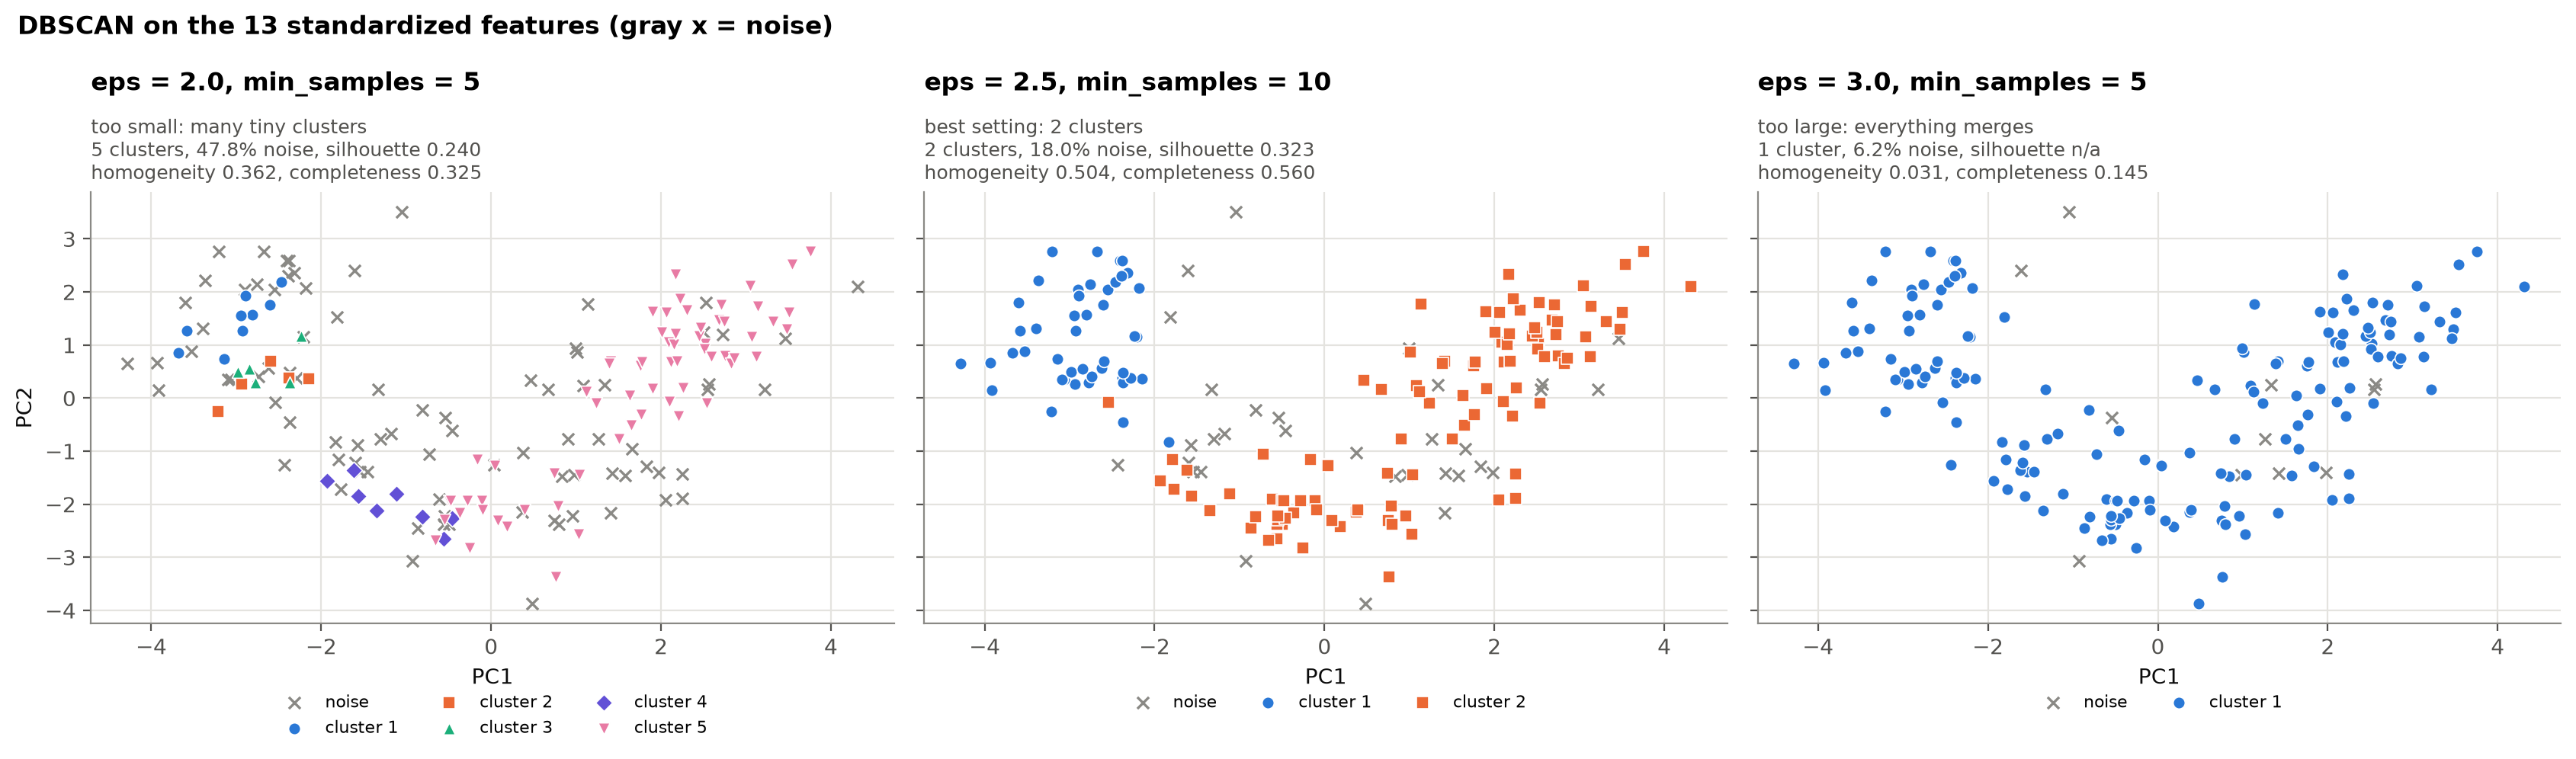

In [15]:
settings = [(2.0, 5, "too small: many tiny clusters"), (2.5, 10, "best setting: 2 clusters"),
            (3.0, 5, "too large: everything merges")]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharex=True, sharey=True)
for ax, (eps, ms, note) in zip(axes, settings):
    r = score(db_labels[(eps, ms)])
    sil = "n/a" if np.isnan(r["silhouette"]) else f"{r['silhouette']:.3f}"
    scatter(ax, db_labels[(eps, ms)], f"eps = {eps}, min_samples = {ms}",
            f"{note}\n{r['clusters']} cluster{'s' if r['clusters'] != 1 else ''}, {r['noise %']:.1f}% noise, silhouette {sil}\n"
            f"homogeneity {r['homogeneity']:.3f}, completeness {r['completeness']:.3f}")
axes[0].set_ylabel("PC2")
fig.suptitle("DBSCAN on the 13 standardized features (gray x = noise)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [16]:
# Where the best DBSCAN setting puts each cultivar
best = db_labels[(2.5, 10)]
pd.crosstab(y.map(dict(enumerate(class_names))), pd.Series(order_by_pc1(best) + 1).replace(0, "noise").values,
            rownames=["true class"], colnames=["DBSCAN cluster"])

DBSCAN cluster,1,2,noise
true class,,,
class_0,0,56,3
class_1,1,45,25
class_2,44,0,4


**Effect of the parameters.**
* **eps too small** (1.5): almost no wine has enough neighbors, so nearly everything is noise (82.6% to 100%).
* **eps around 2 to 2.75**: DBSCAN finds clusters, but never the three cultivars. The best setting, **eps = 2.5,
  min_samples = 10**, finds 2 clusters with 18.0% noise: silhouette 0.323, homogeneity 0.504, completeness 0.560.
  One cluster holds class_2; the other merges class_0 with most of class_1. Most of the noise (25 of 32 wines) is class_1.
* **eps of 3 or more**: almost every wine joins one big cluster (at most a tiny second one forms), so homogeneity
  falls to about 0.03.
* Rows with 100% noise show completeness = 1.000 only because every wine gets the same "noise" label; that value
  means nothing.
* **min_samples** works in the opposite direction: a larger value makes the core-point test stricter, so more wines
  become noise (at eps = 2.25, noise rises from 20.8% with min_samples = 3 to 64.0% with 15).
* **Why DBSCAN struggles here:** it needs low-density gaps between clusters. class_0 and class_1 touch, with class_1
  wines bridging the gap, so at any single density level the two are either joined or broken into noise.

{'clusters': 4, 'noise %': 11.236, 'silhouette': 0.261, 'homogeneity': 0.753, 'completeness': 0.575, 'ARI': 0.663}


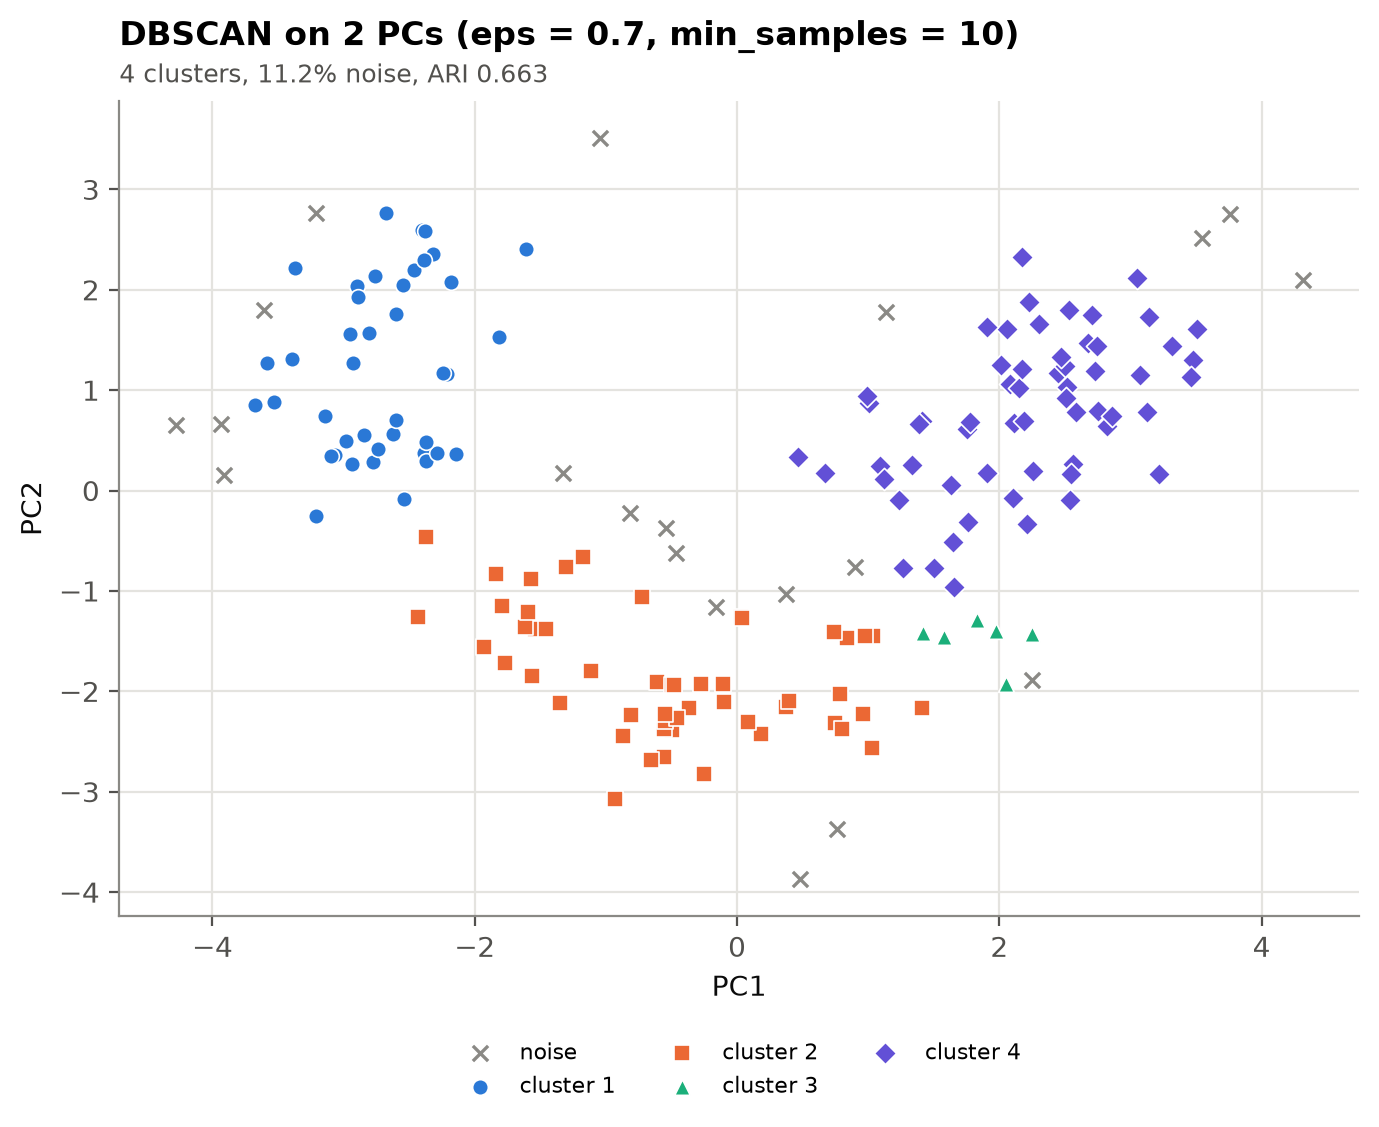

In [17]:
# Extra check: DBSCAN after reducing the data to the 2 principal components.
# In 13 dimensions, distances between wines become similar, so "dense" is harder to define (curse of dimensionality).
pca_db = DBSCAN(eps=0.7, min_samples=10).fit_predict(P)
r = score(pca_db)
print({key: (round(float(v), 3) if isinstance(v, float) else v) for key, v in r.items()})
fig, ax = plt.subplots(figsize=(7, 5.8))
scatter(ax, pca_db, "DBSCAN on 2 PCs (eps = 0.7, min_samples = 10)",
        f"{r['clusters']} clusters, {r['noise %']:.1f}% noise, ARI {r['ARI']:.3f}")
ax.set_ylabel("PC2")
fig.tight_layout()
plt.show()

## Step 4: Analysis and Insights

In [18]:
compare = pd.DataFrame([
    {"method": "Agglomerative, Ward, n = 3", **score(agg_labels[3])},
    {"method": "Agglomerative, complete, n = 3",
     **score(AgglomerativeClustering(n_clusters=3, linkage="complete").fit_predict(Z))},
    {"method": "DBSCAN, eps 2.5, min_samples 10 (13-D)", **score(db_labels[(2.5, 10)])},
    {"method": "DBSCAN, eps 0.7, min_samples 10 (2 PCs)", **score(pca_db)},
]).set_index("method")
compare.round(3)

,clusters,noise %,silhouette,homogeneity,completeness,ARI
method,,,,,,
"Agglomerative, Ward, n = 3",3,0.000,0.277,0.790,0.783,0.790
"Agglomerative, complete, n = 3",3,0.000,0.204,0.616,0.613,0.577
"DBSCAN, eps 2.5, min_samples 10 (13-D)",2,17.978,0.323,0.504,0.560,0.424
"DBSCAN, eps 0.7, min_samples 10 (2 PCs)",4,11.236,0.261,0.753,0.575,0.663


### Comparison

* **Agglomerative clustering with Ward linkage was clearly better** on this dataset: 3 clusters that match the
  cultivars well (homogeneity 0.790, completeness 0.783, ARI 0.790, silhouette 0.277) and no wine left unassigned.
* **DBSCAN on the 13 features never recovered the three cultivars.** Its best result had 2 clusters, 18% noise,
  homogeneity 0.504 and completeness 0.560. Its silhouette (0.323) looks higher than Ward's, but only because the 32
  hardest wines were removed as noise before scoring; it is not a better clustering.
* Reducing to 2 principal components helped DBSCAN a lot (it found the three cultivars plus one small extra cluster,
  ARI 0.663), but it is still below Ward.

### How the parameters shaped the results

* **Hierarchical:** n_clusters sets where the tree is cut. 3 matches the big gap in the dendrogram; fewer merges
  cultivars, more splits them. The linkage method mattered even more: Ward worked, average and single linkage
  chained almost all wines into one cluster.
* **DBSCAN:** eps and min_samples together set the density a cluster must reach. Small eps or large min_samples
  turns most wines into noise; large eps or small min_samples merges everything. The useful range was narrow
  (about eps 2.25 to 2.75), and the k-distance plot was a good guide to it.

### Strengths and weaknesses seen here

* **Agglomerative (Ward):** + the dendrogram shows the structure and suggests the number of clusters;
  + good results on compact, similar-sized groups like these. - The number of clusters (or cut height) must still be
  chosen; - every wine is forced into a cluster, even outliers; - it needs all pairwise distances, so it scales poorly
  to large datasets; - results depend heavily on the linkage.
* **DBSCAN:** + no need to choose the number of clusters; + it labels outliers as noise instead of forcing them into a
  cluster; + it can find clusters of any shape. - It needs clear low-density gaps, which the Wine classes do not have;
  - one global eps cannot fit groups of different density (class_1 is more spread out, so it ends up as noise);
  - it works poorly in many dimensions, as the 2-component result shows.